# Data Coverage EDA: CIQ Transcripts + SEC Filings

A short coverage check of the two text sources for the earnings-surprise signal, side by side:

- **CIQ earnings-call transcripts** (`ciq_transcripts`): one row per earnings call (`keydevid`), deduped to one transcript.
- **SEC filings** (`wrdssec`): 10-K, 10-Q, and 8-K **Item 2.02** (the earnings press release, usually exhibit EX-99.1).

For each dataset we report events and firms per year (all and US only), region and industry mix, gvkey link rate, missing fields, timing, and how recent the data is. We finish with how much the two datasets overlap. Deeper dives are in `ciq_transcripts_eda.ipynb` and `sec_analytics_eda.ipynb`.

Definitions: **US** = headquartered in the US (CIQ company country; for SEC, the Compustat `loc` of the linked gvkey). **Industry** = Compustat GICS sector via gvkey, so both datasets use the same scheme. **Region** = the CIQ region scheme, with the US and Canada split out.

In [1]:
import warnings
import wrds
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings('ignore', category=DeprecationWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# Same chart style as the other notebooks; categorical colors in fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300'
SERIES = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]
INK, INK2, SURFACE = '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2, 'text.color': INK,
    'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e8e7e3', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'figure.figsize': (10, 4), 'figure.dpi': 110, 'lines.linewidth': 2, 'legend.frameon': False,
})
kfmt = mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f}k')
pct = mtick.PercentFormatter(1, decimals=0)
plt.rcParams['axes.formatter.useoffset'] = False
YEARS = mtick.MaxNLocator(integer=True)

THIS_YEAR = pd.Timestamp.today().year
LAST_FULL = THIS_YEAR - 1
SEL_YEARS = [2008, 2012, 2016, 2020, 2024, LAST_FULL] if LAST_FULL != 2024 else [2008, 2012, 2016, 2020, 2024]
GICS = {10: 'Energy', 15: 'Materials', 20: 'Industrials', 25: 'Consumer Discretionary', 30: 'Consumer Staples',
        35: 'Health Care', 40: 'Financials', 45: 'Information Technology', 50: 'Communication Services',
        55: 'Utilities', 60: 'Real Estate'}

db = wrds.Connection()  # uses pgpass credentials

Loading library list...


Done


## 1. Load the event tables

All joins and dedup run on the server. We pull one row per event: about 0.4M calls, 0.95M 10-K/10-Qs and 0.4M earnings 8-Ks.

In [2]:
# Shared lookups: country -> region (CIQ scheme) and gvkey -> HQ region + GICS sector (Compustat)
geo = db.raw_sql('select isocountry2, isocountry3, region from ciq.ciqcountrygeo')

def region_of(iso2, region):
    iso2 = pd.Series(iso2).fillna('')
    return pd.Series(np.select([iso2.eq('US'), iso2.eq('CA')], ['United States', 'Canada'],
                               default=pd.Series(region).fillna('Unknown').astype(str)), index=iso2.index)

comp = db.raw_sql('''
    select gvkey, loc, gsector from comp.company
    union all
    select gvkey, loc, gsector from comp.g_company where gvkey not in (select gvkey from comp.company)
''')  # North America first, then Global
comp = comp.merge(geo.rename(columns={'isocountry3': 'loc'}), on='loc', how='left')
comp['region'] = region_of(comp.isocountry2, comp.region)
comp['sector'] = pd.to_numeric(comp.gsector, errors='coerce').map(GICS)
comp = comp[['gvkey', 'region', 'sector']]

# --- CIQ: one transcript per earnings call (prefer Final, then latest), plus version count
calls = db.raw_sql('''
    with v as (
        select keydevid, count(*) as n_versions, min(transcriptcreationdate_utc) as first_created
        from ciq_transcripts.wrds_transcript_detail where keydeveventtypeid = 48 group by 1
    ), dedup as (
        select distinct on (keydevid)
               keydevid, transcriptid, companyid, mostimportantdateutc as call_date,
               mostimportanttimeutc as call_time_utc, transcriptpresentationtypename as presentation,
               transcriptcreationdate_utc as created_date, audiolengthsec
        from ciq_transcripts.wrds_transcript_detail
        where keydeveventtypeid = 48
        order by keydevid, (transcriptpresentationtypeid = 5) desc,
                 transcriptcreationdate_utc desc, transcriptcreationtime_utc desc, transcriptid desc
    )
    select d.*, v.n_versions, v.first_created, g.isocountry2, g.region as ciq_region
    from dedup d join v using (keydevid)
    left join ciq.ciqcompany c on c.companyid = d.companyid
    left join ciq.ciqcountrygeo g on g.countryid = c.countryid
''', date_cols=['call_date', 'created_date', 'first_created'])
calls['year'] = calls.call_date.dt.year
calls['region'] = region_of(calls.isocountry2, calls.ciq_region)
calls['us'] = calls.region.eq('United States')

# Date-aware companyid -> gvkey (open-ended when start/end is missing), primary link first
gv = db.raw_sql('select companyid, gvkey, startdate, enddate, primaryflag from ciq.wrds_gvkey',
                date_cols=['startdate', 'enddate'])
lk = calls[['keydevid', 'companyid', 'call_date']].merge(gv, on='companyid')
ok = (lk.startdate.isna() | (lk.call_date >= lk.startdate)) & (lk.enddate.isna() | (lk.call_date <= lk.enddate))
lk = lk[ok].sort_values('primaryflag', ascending=False).drop_duplicates('keydevid')
calls = calls.merge(lk[['keydevid', 'gvkey']], on='keydevid', how='left').merge(comp[['gvkey', 'sector']], on='gvkey', how='left')

# --- SEC: one row per 10-K/10-Q accession, gvkey from wrdssec.forms
filings = db.raw_sql('''
    select distinct on (w.accession)
           w.accession, w.cik, w.form, w.fdate, w.rdate, w.secadate, w.secatime, g.gvkey
    from wrdssec.wrds_forms w
    left join wrdssec.forms g on g.fname = w.fname and g.cik = w.cik and g.form = w.form
    where w.form in ('10-K', '10-K405', '10-KT', '10-Q') and w.fdate >= '1994-01-01'
    order by w.accession, (g.gvkey is null), w.cik
''', date_cols=['fdate', 'rdate', 'secadate'])
filings['ftype'] = np.where(filings.form == '10-Q', '10-Q', '10-K')

# --- SEC: one row per Item 2.02 8-K (legacy code 12 = same item), with exhibit flags
ea8k = db.raw_sql('''
    with e as (
        select distinct on (i.accession) i.accession, i.cik, i.fdate, i.secadate, i.secatime, g.gvkey
        from wrdssec.items8k i
        left join wrdssec.forms g on g.fname = i.fname and g.cik = i.cik and g.form = i.form
        where i.form = '8-K' and i.nitem in ('2.02', '12') and i.fdate >= '2004-01-01'
        order by i.accession, (g.gvkey is null), i.cik
    ), x as (
        select accession, bool_or(type = 'EX-99.1') as has_ex991
        from wrdssec.exhibits where form = '8-K' and type ~ '^EX-99' and fdate >= '2004-01-01'
        group by 1
    )
    select e.*, coalesce(x.has_ex991, false) as has_ex991, (x.accession is not null) as has_ex99
    from e left join x using (accession)
''', date_cols=['fdate', 'secadate'])

for df in (filings, ea8k):
    df['year'] = df.fdate.dt.year
filings = filings.merge(comp, on='gvkey', how='left')
ea8k = ea8k.merge(comp, on='gvkey', how='left')
filings['us'] = filings.region.eq('United States')
ea8k['us'] = ea8k.region.eq('United States')
k10, q10 = filings[filings.ftype == '10-K'], filings[filings.ftype == '10-Q']

print(f'CIQ earnings calls: {len(calls):,} | 10-K: {len(k10):,} | 10-Q: {len(q10):,} | 8-K Item 2.02: {len(ea8k):,}')

CIQ earnings calls: 412,611 | 10-K: 250,370 | 10-Q: 696,561 | 8-K Item 2.02: 432,292


## 2. At a glance

In [3]:
def glance(df, date_col, id_col, label):
    d = df[df.year == LAST_FULL]
    return {'dataset': label, 'events': len(df), 'firms (all time)': df[id_col].nunique(),
            'first date': df[date_col].min().date(), 'latest date': df[date_col].max().date(),
            f'events {LAST_FULL}': len(d), f'firms {LAST_FULL}': d[id_col].nunique(),
            f'US share of events {LAST_FULL}': d.us.mean(), 'gvkey link rate': df.gvkey.notna().mean(),
            f'gvkey link rate {LAST_FULL}': d.gvkey.notna().mean()}

summary = pd.DataFrame([
    glance(calls, 'call_date', 'companyid', 'CIQ earnings calls'),
    glance(k10, 'fdate', 'cik', 'SEC 10-K'),
    glance(q10, 'fdate', 'cik', 'SEC 10-Q'),
    glance(ea8k, 'fdate', 'cik', 'SEC 8-K Item 2.02'),
]).set_index('dataset')
summary.style.format({c: '{:,.0f}' for c in summary.columns if c.startswith(('events', 'firms'))}
                     | {c: '{:.1%}' for c in summary.columns if 'share' in c or 'rate' in c})

,events,firms (all time),first date,latest date,events 2025,firms 2025,US share of events 2025,gvkey link rate,gvkey link rate 2025
dataset,,,,,,,,,
CIQ earnings calls,"412,611","16,603",2004-09-08,2026-10-09,"30,685","9,260",39.7%,99.7%,99.7%
SEC 10-K,"250,370","39,090",1994-01-06,2026-10-16,"6,453","6,308",73.6%,75.9%,78.7%
SEC 10-Q,"696,561","29,762",1994-01-04,2026-10-19,"16,856","5,834",84.1%,83.3%,89.8%
SEC 8-K Item 2.02,"432,292","13,066",2004-01-02,2026-10-19,"16,824","4,192",94.2%,95.3%,98.6%


Firms are counted by native ID (CIQ `companyid`, SEC `cik`). For SEC, "US" requires a gvkey link, so unlinked filers (mostly ABS and commodity trusts) count as non-US.

## 3. Data freshness

,latest
source,
CIQ: latest earnings-call date,2026-10-09
CIQ: latest transcript created,2026-10-11
SEC: filing index (wrds_forms),2026-10-19
SEC: 8-K items (items8k),2026-10-19
SEC: exhibits,2026-10-19
SEC: LM sentiment (wrds_nlpsa),2026-10-19
SEC: similarity (bow_cossim),2024-12-31
SEC: full text 10-K,2026-10-19
SEC: full text 10-Q,2026-10-19


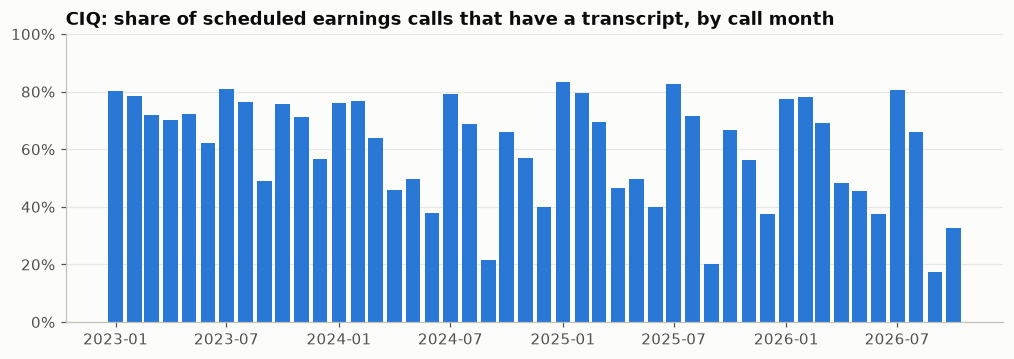

         share with transcript  same month a year earlier
month                                                    
2026-07                    80%                        83%
2026-08                    66%                        72%
2026-09                    17%                        20%


In [4]:
fresh = db.raw_sql('''
    select 'CIQ: latest earnings-call date' as source, max(mostimportantdateutc) as latest
      from ciq_transcripts.wrds_transcript_detail where keydeveventtypeid = 48
    union all select 'CIQ: latest transcript created', max(transcriptcreationdate_utc) from ciq_transcripts.wrds_transcript_detail
    union all select 'SEC: filing index (wrds_forms)', max(fdate) from wrdssec.wrds_forms
    union all select 'SEC: 8-K items (items8k)', max(fdate) from wrdssec.items8k
    union all select 'SEC: exhibits', max(fdate) from wrdssec.exhibits
    union all select 'SEC: LM sentiment (wrds_nlpsa)', max(fdate) from wrdssec.wrds_nlpsa
    union all select 'SEC: similarity (bow_cossim)', max(fdate) from wrdssec.bow_cossim
    union all select 'SEC: full text 10-K', max(filing_date) from wrds_sec_search.filing_10_k
    union all select 'SEC: full text 10-Q', max(filing_date) from wrds_sec_search.filing_10_q
    union all select 'SEC: full text 8-K', max(filing_date) from wrds_sec_search.filing_8_k
''')
display(fresh.set_index('source'))

# CIQ: scheduled earnings calls (key-dev events) and whether a transcript exists yet
sched = db.raw_sql('''
    select date_trunc('month', k.d)::date as month, count(*) as n_scheduled,
           sum((t.keydevid is not null)::int) as n_with_transcript
    from (select distinct keydevid, mostimportantdateutc::date as d from ciq.wrds_keydev
          where keydeveventtypeid = 48 and mostimportantdateutc between '2023-01-01' and current_date) k
    left join (select distinct keydevid from ciq_transcripts.ciqtranscript) t using (keydevid)
    group by 1 order by 1
''', date_cols=['month'])
sched['share'] = sched.n_with_transcript / sched.n_scheduled

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(sched.month, sched.share, width=24, color=BLUE)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1)
ax.set_title('CIQ: share of scheduled earnings calls that have a transcript, by call month')
ax.grid(axis='x', visible=False)
plt.show()
s_ = sched.set_index('month').share
recent = s_.iloc[-4:-1]  # last three complete months
prior = s_.reindex(recent.index - pd.DateOffset(years=1))
print(pd.DataFrame({'share with transcript': recent.values, 'same month a year earlier': prior.values},
                   index=recent.index.strftime('%Y-%m')).to_string(float_format='{:.0%}'.format))

Both sources are current: CIQ through 2026-10-09 (transcripts created through 10-11), and the SEC index, items, exhibits, LM scores and full text through 2026-10-19. The exception is `bow_cossim` (similarity), which stops at 2024-12-31.

CIQ schedules more earnings calls than it transcribes. About 63% of scheduled calls in 2023-2025 have a transcript, with a strong quarterly cycle (about 80% in peak months, 20-40% in off-cycle months when mostly small and non-US firms report). The last three complete months are a few points below the same months a year earlier, consistent with the most recent calls still being processed rather than a coverage break. The delay-reason table in section 8 shows why calls are skipped.

## 4. Events and firms per year: all vs US

In [5]:
def per_year(df, id_col):
    us = df[df.us]
    return pd.DataFrame({'events': df.groupby('year').size(), 'firms': df.groupby('year')[id_col].nunique(),
                         'US events': us.groupby('year').size(), 'US firms': us.groupby('year')[id_col].nunique()})

cov = pd.concat({'CIQ calls': per_year(calls, 'companyid'), 'SEC 10-K': per_year(k10, 'cik'),
                 'SEC 10-Q': per_year(q10, 'cik'), 'SEC 8-K 2.02': per_year(ea8k, 'cik')}, axis=1)
cov.loc[2004:].style.format('{:,.0f}', na_rep='')

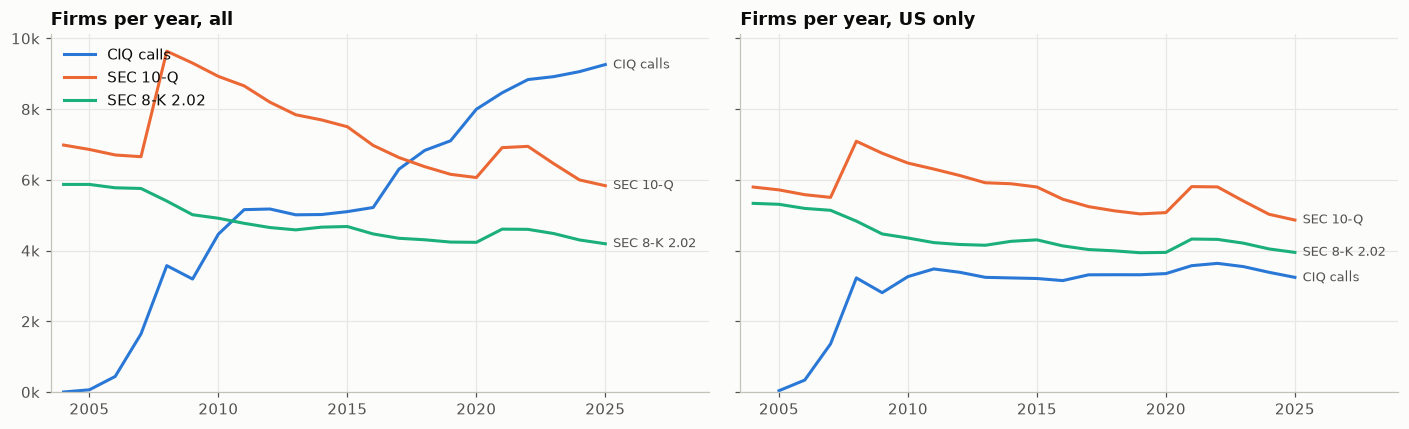

In [6]:
yr = cov.loc[2004:LAST_FULL]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col, title in [(axes[0], 'firms', 'Firms per year, all'), (axes[1], 'US firms', 'Firms per year, US only')]:
    for (src, c) in zip(['CIQ calls', 'SEC 10-Q', 'SEC 8-K 2.02'], [BLUE, ORANGE, AQUA]):
        s = yr[(src, col)]
        ax.plot(s.index, s.values, color=c, label=src)
        ax.text(s.index[-1] + 0.3, s.iloc[-1], src, color=INK2, va='center', fontsize=8.5)
    ax.set_title(title); ax.yaxis.set_major_formatter(kfmt); ax.set_ylim(0)
    ax.set_xlim(2003.5, LAST_FULL + 4)
axes[0].legend(loc='upper left')
plt.tight_layout(); plt.show()

- **CIQ** becomes usable from **2008** (about 10k calls a year, 3.2k US firms) and has grown to about 30k calls and 9.3k firms a year, almost all of the growth outside the US. US coverage has been flat at about 3.2-3.6k firms (12-13.5k calls) a year since 2010.
- **SEC** is complete from **1996**. US filers are declining slowly: about 4.9k US 10-Q filers and 4.0k US firms with an earnings 8-K in 2025. The 2008 jump in 10-Q filers is small companies moving from 10-QSB to 10-Q.
- In the US, CIQ firms (3.2k) are about 80% of firms with an earnings 8-K (4.0k), so the transcript universe is the binding constraint.

## 5. Region

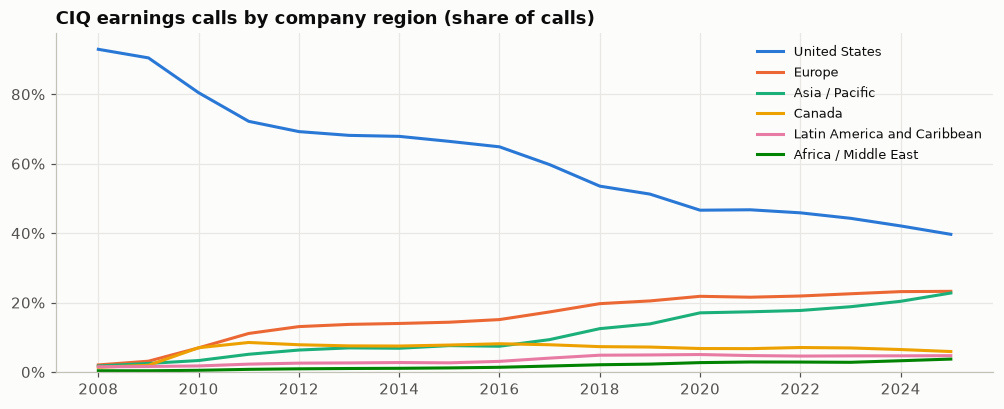

,CIQ calls (firms),SEC 10-K (firms),SEC 8-K 2.02 (firms)
region,,,
Africa / Middle East,4.8%,0.3%,0.3%
Asia / Pacific,25.3%,1.6%,0.6%
Canada,5.3%,1.2%,1.1%
Europe,25.3%,1.4%,1.8%
Latin America and Caribbean,4.4%,0.5%,0.7%
United States,35.0%,74.6%,94.2%
Unlinked,0.0%,20.4%,1.4%


In [7]:
REGIONS = ['United States', 'Europe', 'Asia / Pacific', 'Canada', 'Latin America and Caribbean', 'Africa / Middle East']
reg = calls[calls.year.between(2008, LAST_FULL)].pipe(lambda d: pd.crosstab(d.year, d.region, normalize='index'))

fig, ax = plt.subplots(figsize=(11, 4))
for r_, c in zip(REGIONS, SERIES):
    if r_ in reg:
        ax.plot(reg.index, reg[r_], color=c, label=r_)
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0)
ax.xaxis.set_major_locator(YEARS)
ax.set_title('CIQ earnings calls by company region (share of calls)')
ax.legend(loc='upper right', fontsize=8.5)
plt.show()

def mix(df, id_col):
    d = df[df.year == LAST_FULL].drop_duplicates(id_col)
    return d.region.fillna('Unlinked').value_counts(normalize=True)

pd.DataFrame({'CIQ calls (firms)': mix(calls, 'companyid'), 'SEC 10-K (firms)': mix(k10, 'cik'),
              'SEC 8-K 2.02 (firms)': mix(ea8k, 'cik')}).fillna(0).style.format('{:.1%}') \
    .set_caption(f'Region mix of firms, {LAST_FULL}')

The US share of CIQ calls fell from over 90% (2008) to 40% (2025), as Europe and Asia/Pacific grew to about 23% each. SEC filers are, as expected, mostly US: 94% of earnings-8-K firms. The "Unlinked" 20% of 10-K filers are the ABS and commodity trusts with no gvkey.

## 6. Industry (GICS sector, US firms)

How many US firms per sector file with the SEC, and what share of them also have a CIQ earnings-call transcript that year.

In [8]:
def firms_by_sector(df, year):
    d = df[(df.year == year) & df.us]
    return d.dropna(subset=['gvkey']).groupby('sector').gvkey.nunique()

tab = pd.DataFrame({'US 10-K filers': firms_by_sector(k10, LAST_FULL),
                    'with 8-K 2.02': firms_by_sector(ea8k, LAST_FULL),
                    'with CIQ call': firms_by_sector(calls, LAST_FULL)})
tab.loc['Total'] = tab.sum()
tab['CIQ / 10-K'] = tab['with CIQ call'] / tab['US 10-K filers']
tab['8-K 2.02 / 10-K'] = tab['with 8-K 2.02'] / tab['US 10-K filers']
display(tab.style.format({c: '{:,.0f}' for c in tab.columns[:3]} | {c: '{:.0%}' for c in tab.columns[3:]})
        .set_caption(f'US firms (gvkey) by sector, {LAST_FULL}'))

# Over time: share of US 10-K filers with a CIQ call, by sector
ot = pd.DataFrame({y: firms_by_sector(calls, y) / firms_by_sector(k10, y) for y in SEL_YEARS})
ot.style.format('{:.0%}', na_rep='').set_caption('Share of US 10-K filers with a CIQ earnings call, by sector and year')

,US 10-K filers,with 8-K 2.02,with CIQ call,CIQ / 10-K,8-K 2.02 / 10-K
sector,,,,,
Communication Services,205,170,158,77%,83%
Consumer Discretionary,468,420,381,81%,90%
Consumer Staples,191,156,137,72%,82%
Energy,218,186,158,72%,85%
Financials,759,733,526,69%,97%
Health Care,"1,029",853,561,55%,83%
Industrials,618,539,495,80%,87%
Information Technology,542,482,438,81%,89%
Materials,177,134,125,71%,76%


,2008,2012,2016,2020,2024,2025
sector,,,,,,
Communication Services,65%,56%,64%,78%,75%,77%
Consumer Discretionary,66%,70%,75%,83%,83%,81%
Consumer Staples,59%,47%,55%,62%,70%,72%
Energy,54%,56%,64%,69%,72%,72%
Financials,39%,42%,46%,63%,66%,69%
Health Care,62%,54%,49%,65%,57%,55%
Industrials,67%,65%,68%,78%,79%,80%
Information Technology,69%,72%,73%,78%,80%,81%
Materials,61%,50%,59%,69%,71%,71%


In 2025, 71% of US 10-K filers have a CIQ transcript and 87% file an earnings 8-K. Coverage is lowest in **Health Care (55%)**, where many pre-revenue biotechs don't hold calls, and in Financials (69%, many small banks). It is highest in Consumer Discretionary, Industrials and IT (80-81%). CIQ coverage has risen in every sector since 2008-2012, most in Financials (39% to 69%).

## 7. Completeness by year

Share of events missing each key field, by year. The CIQ content checks (short transcripts, speaker info, empty turns) use a random sample of up to 1,500 calls per year, scored on the server from `wrds_transcript_person`.

In [9]:
YRS = list(range(2008, THIS_YEAR + 1))
heat = dict(cmap='Blues', vmin=0, vmax=0.5)

def miss_by_year(df, fields, years=YRS):
    return pd.DataFrame({name: s_.groupby(df.year).mean() for name, s_ in fields.items()}).T.reindex(columns=years)

# CIQ content sample: per-transcript word count and speaker/turn quality flags
samp = (calls[calls.year >= 2008].groupby('year', group_keys=False)
        .apply(lambda d: d.sample(min(len(d), 1500), random_state=0)))
ids = ','.join(f'({int(i)})' for i in samp.transcriptid)
tq = db.raw_sql(f'''
    with ids(transcriptid) as (values {ids})
    select p.transcriptid,
           sum(coalesce(p.word_count, 0))                                                as words,
           avg((p.speakertypeid is null or p.speakertypename = 'Unknown Speaker')::int) as unknown_speaker,
           avg((coalesce(p.word_count, 0) = 0)::int)                                     as empty_turn,
           avg((p.transcriptpersonname is null)::int)                                    as no_speaker_name,
           avg(case when p.speakertypeid = 3 then (p.companyofperson is null)::int end)  as analyst_no_company
    from ciq_transcripts.wrds_transcript_person p join ids using (transcriptid)
    group by 1
''')
samp = samp.merge(tq, on='transcriptid', how='left')

ciq_miss = pd.concat([
    miss_by_year(calls, {'gvkey': calls.gvkey.isna(), 'country': calls.isocountry2.isna(),
                         'GICS sector': calls.sector.isna(), 'call time': calls.call_time_utc.isna(),
                         'audio length': ~(calls.audiolengthsec.fillna(0) > 0)}),
    miss_by_year(samp, {'no transcript text (sample)': samp.words.isna() | samp.words.eq(0),
                        'transcript < 1,000 words (sample)': samp.words.fillna(0) < 1000}),
    samp.groupby('year')[['unknown_speaker', 'empty_turn', 'no_speaker_name', 'analyst_no_company']].mean()
        .rename(columns={'unknown_speaker': 'turns: unknown speaker type (sample)', 'empty_turn': 'turns: empty text (sample)',
                         'no_speaker_name': 'turns: no speaker name (sample)',
                         'analyst_no_company': 'analyst turns: no firm (sample)'}).T.reindex(columns=YRS),
])
display(ciq_miss.style.format('{:.1%}', na_rep='').background_gradient(**heat)
        .set_caption('CIQ earnings calls: share missing / flagged, by call year'))

k, e8, SEC_YRS = filings, ea8k, list(range(2004, THIS_YEAR + 1))
sec_miss = pd.concat([
    miss_by_year(k, {'10-K/Q: gvkey': k.gvkey.isna(), '10-K/Q: period of report': k.rdate.isna(),
                     '10-K/Q: acceptance time': k.secatime.isna(), '10-K/Q: GICS sector': k.sector.isna()}, SEC_YRS),
    miss_by_year(e8, {'8-K 2.02: gvkey': e8.gvkey.isna(), '8-K 2.02: acceptance time': e8.secatime.isna(),
                      '8-K 2.02: no EX-99.1': ~e8.has_ex991, '8-K 2.02: no EX-99 at all': ~e8.has_ex99}, SEC_YRS),
])
sec_miss.style.format('{:.1%}', na_rep='').background_gradient(**heat) \
    .set_caption('SEC filings: share missing, by filing year')

year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
gvkey,0.3%,0.2%,0.5%,0.6%,0.4%,0.4%,0.4%,0.5%,0.4%,0.3%,0.2%,0.2%,0.2%,0.2%,0.2%,0.3%,0.3%,0.3%,0.2%
country,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
GICS sector,0.3%,0.3%,0.5%,0.7%,0.5%,0.4%,0.4%,0.5%,0.4%,0.3%,0.3%,0.3%,0.5%,0.4%,0.5%,0.6%,0.7%,0.7%,0.6%
call time,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
audio length,98.9%,90.0%,25.4%,13.8%,0.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
no transcript text (sample),0.3%,0.1%,0.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
"transcript < 1,000 words (sample)",0.5%,0.1%,0.4%,0.1%,0.3%,0.1%,0.1%,0.2%,0.1%,0.1%,0.5%,0.3%,0.3%,0.5%,0.2%,0.3%,0.3%,1.1%,0.8%
turns: unknown speaker type (sample),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
turns: empty text (sample),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
turns: no speaker name (sample),0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
10-K/Q: gvkey,18.8%,20.3%,20.0%,19.6%,21.2%,21.3%,20.6%,20.7%,19.5%,19.4%,18.9%,18.3%,17.6%,16.9%,15.8%,14.8%,13.2%,12.9%,12.6%,12.7%,12.9%,13.3%,14.7%
10-K/Q: period of report,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,1.2%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
10-K/Q: acceptance time,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
10-K/Q: GICS sector,19.4%,20.9%,20.7%,20.7%,22.6%,22.5%,21.6%,21.7%,20.6%,20.6%,20.0%,19.5%,18.9%,18.3%,17.4%,16.6%,15.7%,19.0%,21.0%,17.7%,16.4%,17.2%,21.0%
8-K 2.02: gvkey,6.4%,6.7%,7.0%,7.0%,6.7%,6.5%,6.4%,6.5%,6.4%,5.7%,4.9%,4.5%,4.4%,3.8%,3.3%,3.0%,2.8%,2.2%,1.9%,1.9%,1.7%,1.4%,1.1%
8-K 2.02: acceptance time,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
8-K 2.02: no EX-99.1,32.7%,25.7%,21.6%,18.3%,16.2%,14.8%,12.5%,13.1%,14.3%,16.0%,15.8%,12.6%,8.7%,8.2%,7.4%,6.9%,6.9%,5.9%,5.0%,9.7%,5.2%,5.3%,5.3%
8-K 2.02: no EX-99 at all,6.3%,4.6%,3.7%,2.9%,2.8%,2.4%,2.0%,2.0%,2.2%,2.2%,2.0%,2.0%,2.0%,1.8%,1.7%,1.5%,2.0%,1.7%,1.3%,1.5%,1.6%,1.6%,1.7%


- **CIQ:** the event-level fields are essentially complete in every year: gvkey 99.5-99.8%, sector 99.3%+, country and call time 100%. **Audio length** is missing for almost all 2008-2009 calls, 25% in 2010, 14% in 2011, and is complete from 2012. Content quality is clean: virtually no calls without text, about 0.1-0.5% of transcripts under 1,000 words (about 1% in 2025-2026), and no unknown-speaker, empty or unnamed turns in the sample. One real gap: **the analyst's firm is empty for 100% of analyst turns since 2012** (`companyofperson`), so analyst-to-broker matching would need the `proid` professional ID instead.
- **SEC 10-K/10-Q:** `gvkey` is missing for 19-21% of filings until 2014, falling to about 13% from 2020, and the gaps are mostly trusts. Period of report and acceptance time are complete from 2004 (acceptance time is largely missing before then).
- **SEC 8-K 2.02:** gvkey gaps fell from about 7% to 1%. The share **without an EX-99.1** fell from 33% (2004) to about 5% (2022-2026, with a one-off 10% in 2023). Only 1.5-2% have no EX-99 exhibit at all, so the rest attach the press release under another number (EX-99, EX-99.01, ...).

## 8. Document length, excluding XBRL

Words per document, as quantiles by year. Bar = 25th-75th percentile, tick = median, whisker = 10th-90th percentile.

- **CIQ:** words per transcript (the same sample as above).
- **SEC:** a random sample of 150 filings per form per year. The text is cut on the server: the **main document** of each 10-K / 10-Q (the first `<DOCUMENT>`), and the **EX-99.1** document of each Item 2.02 8-K. XBRL exhibits and rendering files are excluded. Orange dots show the median `wrds_nlpsa` word count for the full submission, to show how much XBRL adds.

Sampled documents: 10-K 3,450, 10-Q 3,450, EX-99.1 3,450, CIQ 28,488


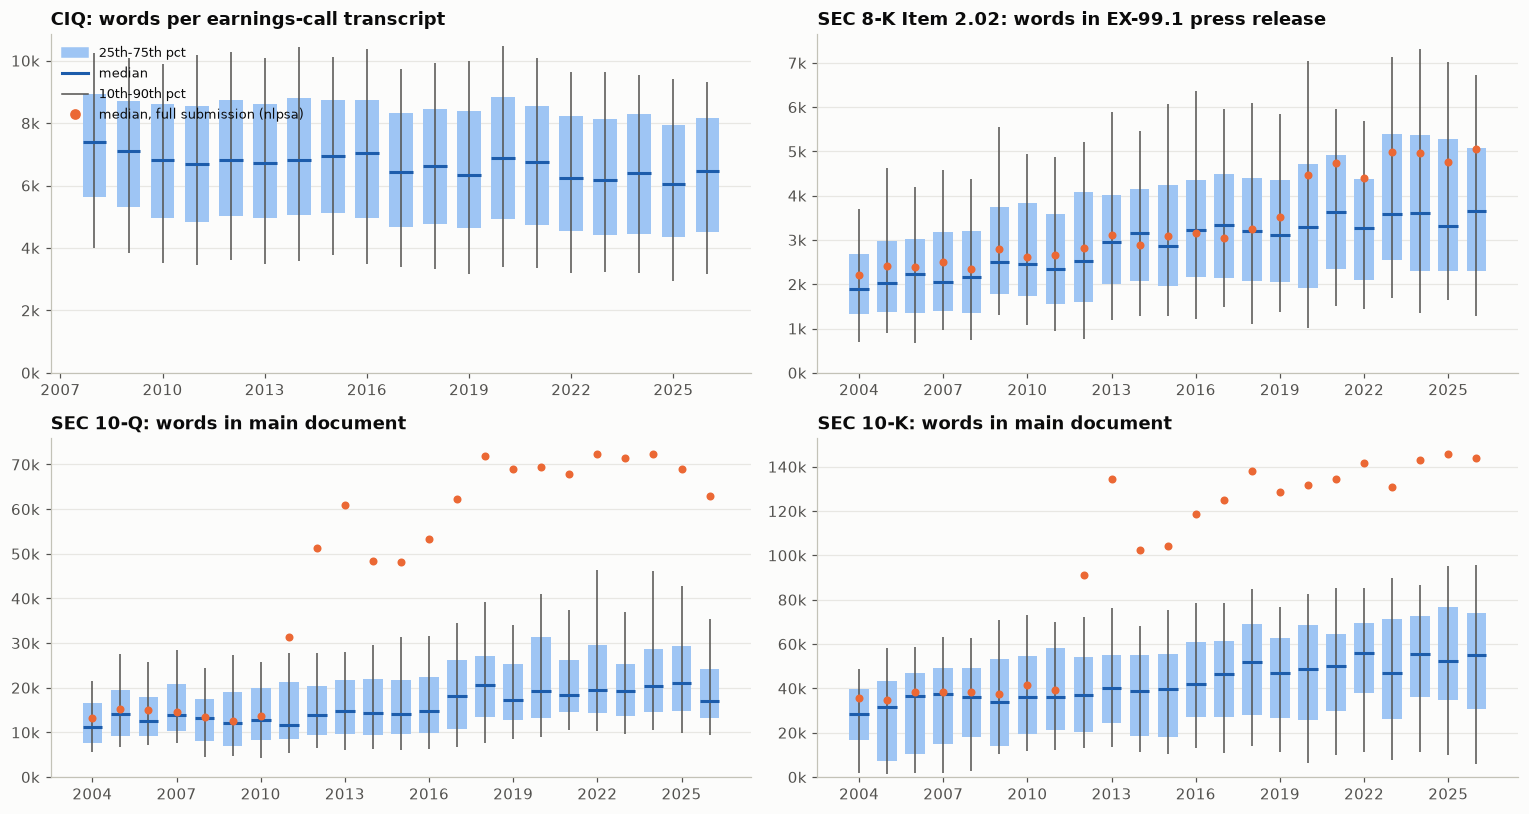

year,2004,2008,2012,2016,2020,2024,2025,2026
CIQ transcript,,"7,381","6,808","7,054","6,882","6,405","6,043","6,461"
8-K EX-99.1,"1,884","2,154","2,526","3,227","3,286","3,598","3,306","3,658"
10-Q main doc,"11,262","13,122","13,997","14,734","19,330","20,430","21,088","16,997"
10-Q full submission,"13,326","13,458","51,212","53,272","69,525","72,404","68,938","63,022"
10-K main doc,"28,596","36,318","37,234","42,090","48,850","55,732","52,458","55,016"
10-K full submission,"35,690","38,355","90,977","118,579","131,766","143,170","145,570","144,004"


In [10]:
def sample_ids(df, n=150, years=range(2004, THIS_YEAR + 1)):
    d = df[df.year.isin(years)]
    return d.groupby('year', group_keys=False).apply(lambda g: g.sample(min(len(g), n), random_state=0))

def doc_words(tbl, sample, extract):
    vals = ','.join(f"('{a}')" for a in sample.accession)
    out = db.raw_sql(f'''
        with ids(accession) as (values {vals}),
        nl as (select distinct on (accession) accession, word_count from wrdssec.wrds_nlpsa
               where accession in (select accession from ids))
        select f.accession,
               coalesce(array_length(regexp_split_to_array(btrim({extract}), '[[:space:]]+'), 1), 0) as words,
               nl.word_count as words_full_submission
        from wrds_sec_search.{tbl} f join ids using (accession) left join nl using (accession)
    ''')
    return sample[['accession', 'year']].merge(out, on='accession')

MAIN = "split_part(split_part(f.filing, '</TEXT>', 1), '<TEXT>', 2)"
EX991 = "split_part(split_part(split_part(f.filing, '<TYPE>EX-99.1', 2), '</TEXT>', 1), '<TEXT>', 2)"
len_10k = doc_words('filing_10_k', sample_ids(filings[filings.form == '10-K']), MAIN)
len_10q = doc_words('filing_10_q', sample_ids(filings[filings.form == '10-Q']), MAIN)
len_ex = doc_words('filing_8_k', sample_ids(ea8k[ea8k.has_ex991]), EX991)
print(f'Sampled documents: 10-K {len(len_10k):,}, 10-Q {len(len_10q):,}, EX-99.1 {len(len_ex):,}, CIQ {samp.words.notna().sum():,}')

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
IQR, MED = '#9ec5f4', '#1c5cab'

def qbars(ax, df, col, title, full_col=None):
    q = df.groupby('year')[col].quantile([.1, .25, .5, .75, .9]).unstack()
    x = q.index.values
    ax.vlines(x, q[0.1], q[0.9], color=INK2, lw=1)
    ax.bar(x, q[0.75] - q[0.25], bottom=q[0.25], width=0.7, color=IQR)
    ax.hlines(q[0.5], x - 0.35, x + 0.35, color=MED, lw=2)
    if full_col is not None:
        ax.scatter(x, df.groupby('year')[full_col].median().reindex(x), s=18, color=ORANGE, zorder=3)
    ax.set_title(title); ax.yaxis.set_major_formatter(kfmt); ax.set_ylim(0)
    ax.xaxis.set_major_locator(YEARS); ax.grid(axis='x', visible=False)

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
qbars(axes[0, 0], samp.dropna(subset=['words']), 'words', 'CIQ: words per earnings-call transcript')
qbars(axes[0, 1], len_ex, 'words', 'SEC 8-K Item 2.02: words in EX-99.1 press release', 'words_full_submission')
qbars(axes[1, 0], len_10q, 'words', 'SEC 10-Q: words in main document', 'words_full_submission')
qbars(axes[1, 1], len_10k, 'words', 'SEC 10-K: words in main document', 'words_full_submission')
axes[0, 0].legend(handles=[Patch(color=IQR, label='25th-75th pct'), Line2D([], [], color=MED, lw=2, label='median'),
                           Line2D([], [], color=INK2, lw=1, label='10th-90th pct'),
                           Line2D([], [], marker='o', ls='', color=ORANGE, label='median, full submission (nlpsa)')],
                  loc='upper left', fontsize=8.5)
plt.tight_layout(); plt.show()

med = pd.DataFrame({'CIQ transcript': samp.groupby('year').words.median(),
                    '8-K EX-99.1': len_ex.groupby('year').words.median(),
                    '10-Q main doc': len_10q.groupby('year').words.median(),
                    '10-Q full submission': len_10q.groupby('year').words_full_submission.median(),
                    '10-K main doc': len_10k.groupby('year').words.median(),
                    '10-K full submission': len_10k.groupby('year').words_full_submission.median()})
med.loc[[y for y in [2004] + SEL_YEARS + [THIS_YEAR] if y in med.index]].T.style.format('{:,.0f}', na_rep='') \
    .set_caption('Median words per document')

- **CIQ transcripts** are stable at a median of about 6-7k words (interquartile range about 4.5-8.5k), drifting slightly down since 2016.
- **EX-99.1 press releases** have nearly doubled: median 1.9k words (2004) to 3.3-3.7k (2023-2026), and the upper tail widened (90th percentile about 7k). The full 8-K submission is only modestly longer: close to EX-99.1 until 2018, then about 1.5k words more once inline-XBRL cover pages arrive (2019+).
- **10-Q / 10-K main documents** grew steadily: 10-Q median 11k to 20k words, and 10-K median 29k to 52-56k. The **full submission** jumps to 3-4x the main document from 2011-2012 (10-K median about 145k), which is the XBRL phase-in. Any length or tone measure on 10-K/10-Q text should use the main document, as here.
- For LLM context budgets: a transcript plus a press release is about 10k words (about 13k tokens) at the median. A 10-K main document is about 55k words (about 70k tokens), so 10-Ks need section extraction (MD&A, Risk Factors) rather than being sent whole.

## 9. CIQ specifics: versions, panel, data quality

In [11]:
# Share of events that have each version type, by call year
vt = db.raw_sql('''
    select extract(year from mostimportantdateutc)::int as year, 'presentation: ' || transcriptpresentationtypename as kind,
           count(distinct keydevid) as n from ciq_transcripts.wrds_transcript_detail where keydeveventtypeid = 48 group by 1, 2
    union all
    select extract(year from mostimportantdateutc)::int, 'collection: ' || transcriptcollectiontypename,
           count(distinct keydevid) from ciq_transcripts.wrds_transcript_detail where keydeveventtypeid = 48 group by 1, 2
''')
ev = calls.groupby('year').size()
vshare = vt.pivot(index='kind', columns='year', values='n').div(ev, axis=1)
vshare.loc['mean versions per event'] = calls.groupby('year').n_versions.mean()
display(vshare[SEL_YEARS + [THIS_YEAR]].style.format('{:.2f}', na_rep='')
        .set_caption('Share of earnings calls with at least one version of each type (last row: mean versions)'))

# Panel: firm-years with all four quarterly calls
cy = calls.groupby(['companyid', 'year']).agg(n=('keydevid', 'size'), us=('us', 'first'))
cy = cy[cy.index.get_level_values('year').isin(SEL_YEARS)]
panel = pd.DataFrame({'all firms': cy.groupby('year').n.apply(lambda s: (s >= 4).mean()),
                      'US firms': cy[cy.us].groupby('year').n.apply(lambda s: (s >= 4).mean())})
display(panel.T.style.format('{:.0%}').set_caption('Share of firm-years with 4+ earnings calls'))

per_firm = calls.groupby('companyid').size()
dups = calls.duplicated(['companyid', 'call_date'], keep=False).mean()
wkend = calls.call_date.dt.dayofweek.ge(5).mean()
print(f'Calls per firm (all time): median {per_firm.median():.0f}, p90 {per_firm.quantile(.9):.0f}')
print(f'Same company + same date under different keydevids: {dups:.2%} of calls')
print(f'Calls dated on a weekend (UTC date): {wkend:.2%}')

delay = db.raw_sql('''
    select coalesce(t.delayreasontypename, d.delayreasontypeid::text) as delay_reason,
           bool_or(t.iscancelledflag = 1) as cancelled, count(*) as n
    from ciq_transcripts.ciqtranscriptdelayreason d
    left join ciq_transcripts.ciqtranscriptdelayreasontype t using (delayreasontypeid)
    group by 1 order by 2 desc
''')
delay.style.format({'n': '{:,.0f}'}).set_caption('Transcript delay reasons (ciqtranscriptdelayreason)')

year,2008,2012,2016,2020,2024,2025,2026
kind,,,,,,,
collection: AI Preliminary Copy,,,,,,,0.04
collection: Audited Copy,0.03,0.47,0.71,0.84,0.34,0.21,0.16
collection: EV Copy,,,,0.04,0.26,0.22,0.16
collection: Edited Copy,0.07,0.73,1.00,0.97,0.74,0.79,0.84
collection: Proofed Copy,0.01,0.79,1.00,0.81,0.18,0.21,0.20
collection: SA Audited Copy,,0.18,,,,,
collection: SA Edited Copy,0.99,0.07,,,,,
collection: SA Proofed Copy,,0.21,,,,,
collection: SA Spellchecked Copy,,0.21,,,,,


year,2008,2012,2016,2020,2024,2025
all firms,43%,74%,72%,66%,65%,65%
US firms,46%,85%,84%,85%,86%,87%


Calls per firm (all time): median 18, p90 65
Same company + same date under different keydevids: 1.38% of calls
Calls dated on a weekend (UTC date): 0.36%


,delay_reason,cancelled,n
0,Cancelled- Special Call / Not Covered,True,165
1,Cancelled- Foreign Language,True,"1,952"
2,Event Cancelled,True,22
3,Cancelled- No Audio,True,"12,111"
4,Cancelled- Limited to Shareholders,True,9
5,Event Postponed (New Time Unknown),False,86
6,IMPT EXMPT - Late Add,False,"10,424"
7,IMPT EXMPT - No English Audio,False,174
8,IMPT EXMPT - Client Request,False,"3,982"
9,IMPT EXMPT - Long Call,False,"5,023"


- **Versions:** every call has a Final version, and since 2012 almost all also have a Preliminary (spellchecked) one. Versions per call peaked at about 4.2 (2020) and are now about 2.6. *EV Copy* appears from 2020 and *AI Preliminary Copy* from 2026 (4% of calls). Before about 2012 a separate set of *SA* collection types is used.
- **Panel:** 85-87% of US firm-years have all four quarterly calls (since 2012), against about 65% overall, because many non-US firms report semi-annually. The median firm has 18 calls in total.
- **Quality:** 1.4% of calls share a company and date with another `keydevid` (likely duplicate events, worth deduping on company + date). Short transcripts and speaker gaps by year are in section 7.
- **Delay reasons:** the largest groups are *Cancelled – No Audio* (12k), *Exempt – No Audio* (10k), *Exempt – Late Add* (10k) and *Exempt – Long Call* (5k). These explain most scheduled calls that never get a transcript.

## 10. SEC specifics: earnings 8-Ks, amendments, foreign filers, full text

In [12]:
e = ea8k.groupby('year').agg(n_8k=('accession', 'size'), ex99_1=('has_ex991', 'mean'),
                             any_ex99=('has_ex99', 'mean'), gvkey=('gvkey', lambda s: s.notna().mean()))
display(e.loc[[2004] + SEL_YEARS + [THIS_YEAR]].T.style.format('{:.1%}').format('{:,.0f}', subset=pd.IndexSlice[['n_8k'], :])
        .set_caption('Item 2.02 8-Ks: count and share with EX-99.1 / any EX-99 / gvkey'))

# Firms that file 10-Qs but never furnish an earnings 8-K
yr_q = q10[(q10.year == LAST_FULL) & q10.us].gvkey.dropna().unique()
yr_8k = set(ea8k[ea8k.year == LAST_FULL].gvkey.dropna())
print(f'US 10-Q filers in {LAST_FULL} with no Item 2.02 8-K that year: {np.mean([g not in yr_8k for g in yr_q]):.1%} of {len(yr_q):,}')

oth = db.raw_sql('''
    select extract(year from fdate)::int as year, form, count(distinct accession) as n
    from wrdssec.wrds_forms
    where form in ('10-K/A', '10-Q/A', 'NT 10-K', 'NT 10-Q', '20-F', '40-F', '6-K') group by 1, 2
''').pivot(index='form', columns='year', values='n')
display(oth[SEL_YEARS].style.format('{:,.0f}').set_caption('Amendments, late-filing notices and foreign-issuer forms per year'))

# Full text: rows vs index, and near-empty submissions (< 2 kB stored)
ft = db.raw_sql('''
    select 'filing_10_k' as tbl, form, count(*) as n_rows, sum((pg_column_size(filing) < 2000)::int) as n_near_empty
      from wrds_sec_search.filing_10_k group by 1, 2
    union all select 'filing_10_q', form, count(*), sum((pg_column_size(filing) < 2000)::int) from wrds_sec_search.filing_10_q group by 1, 2
    union all select 'filing_8_k', form, count(*), sum((pg_column_size(filing) < 2000)::int) from wrds_sec_search.filing_8_k group by 1, 2
''')
idx = db.raw_sql('''
    select form, count(distinct accession) as n_index from wrdssec.wrds_forms
    where form in ('10-K', '10-K/A', '10-Q', '10-Q/A', '8-K', '8-K/A') group by 1
''')
ft = ft.merge(idx, on='form', how='left')
ft['rows / index'] = ft.n_rows / ft.n_index
ft.style.format({'n_rows': '{:,.0f}', 'n_near_empty': '{:,.0f}', 'n_index': '{:,.0f}', 'rows / index': '{:.1%}'})

year,2004,2008,2012,2016,2020,2024,2025,2026
n_8k,"22,042","21,784","18,448","18,016","17,172","17,089","16,824","12,559"
ex99_1,67.3%,83.8%,85.7%,91.3%,93.1%,94.8%,94.7%,94.7%
any_ex99,93.7%,97.2%,97.8%,98.0%,98.0%,98.4%,98.4%,98.3%
gvkey,93.6%,93.3%,93.6%,95.6%,97.2%,98.3%,98.6%,98.9%


US 10-Q filers in 2025 with no Item 2.02 8-K that year: 20.2% of 4,863


year,2008,2012,2016,2020,2024,2025
form,,,,,,
10-K/A,"1,771","1,815","1,129",905,859,708
10-Q/A,"1,468","3,019",860,491,481,287
20-F,799,715,677,738,"1,009","1,077"
40-F,139,152,125,122,145,142
6-K,"23,011","21,042","20,737","22,912","26,765","27,412"
NT 10-K,"2,292","1,571","1,209",713,968,732
NT 10-Q,"3,670","2,899","2,132","1,065","1,664","1,151"


,tbl,form,n_rows,n_near_empty,n_index,rows / index
0,filing_10_k,10-K,"229,560",69,"229,574",100.0%
1,filing_10_k,10-K/A,"46,739",79,"46,740",100.0%
2,filing_10_q,10-Q,"696,559",173,"696,564",100.0%
3,filing_10_q,10-Q/A,"46,368",188,"46,368",100.0%
4,filing_8_k,8-K,"2,032,582","6,975","2,032,586",100.0%
5,filing_8_k,8-K/A,"84,979",396,"84,973",100.0%


- **Earnings 8-Ks:** 98% have an EX-99 exhibit, and 95% use the EX-99.1 label specifically (since about 2020). LM scores (`wrds_nlpsa`) exist for 100% of them in every year.
- **No earnings 8-K:** 20% of US 10-Q filers in 2025 never furnish an Item 2.02 8-K, mostly small firms that report results only in the 10-Q.
- **Amendments and late filings** have fallen since 2012 (10-Q/A from 3.0k to 0.3k a year). NT 10-K / NT 10-Q notices run at about 0.7k / 1.2k a year. **Foreign issuers** file about 27k 6-Ks and 1.1k 20-Fs a year, so ADRs would need a separate pipeline.
- **Full text:** row counts match the index at 100.0%. Near-empty submissions (< 2 kB stored) are rare: 0.03% of 10-Ks/10-Qs and 0.3% of 8-Ks.

## 11. Timing by year

In [13]:
def hour(df):
    return pd.to_timedelta(df.secatime.astype(str), errors='coerce').dt.total_seconds() / 3600

calls['first_lag'] = (calls.first_created - calls.call_date).dt.days
calls['final_lag'] = (calls.created_date - calls.call_date).dt.days
filings['lag'] = (filings.fdate - filings.rdate).dt.days
ea8k['hour'] = hour(ea8k)
t = pd.DataFrame({
    'CIQ: any version same day': calls.groupby('year').first_lag.apply(lambda s: (s <= 0).mean()),
    'CIQ: median days to selected version': calls.groupby('year').final_lag.median(),
    '10-Q: median days after period end': filings[filings.ftype == '10-Q'].groupby('year').lag.median(),
    '10-K: median days after period end': filings[filings.ftype == '10-K'].groupby('year').lag.median(),
    '8-K 2.02: accepted outside 9:30-16:00 ET': ea8k.groupby('year').hour.apply(lambda s: ((s < 9.5) | (s >= 16)).mean()),
    '8-K 2.02: fdate after acceptance date': ea8k.assign(nx=ea8k.fdate > ea8k.secadate).groupby('year').nx.mean(),
})
shares = ['CIQ: any version same day', '8-K 2.02: accepted outside 9:30-16:00 ET', '8-K 2.02: fdate after acceptance date']
t.loc[SEL_YEARS + [THIS_YEAR]].T.style.format('{:.0%}', subset=pd.IndexSlice[shares, :]) \
    .format('{:.0f}', subset=pd.IndexSlice[[c for c in t.columns if c not in shares], :])

year,2008,2012,2016,2020,2024,2025,2026
CIQ: any version same day,16%,76%,84%,84%,83%,84%,83%
CIQ: median days to selected version,59,1,1,30,1,1,1
10-Q: median days after period end,42,40,40,39,39,38,38
10-K: median days after period end,77,76,74,72,73,71,71
8-K 2.02: accepted outside 9:30-16:00 ET,70%,79%,87%,92%,95%,95%,95%
8-K 2.02: fdate after acceptance date,3%,3%,2%,5%,3%,3%,3%


- **CIQ:** since 2012, 83-84% of calls have *some* version on the call date, and the selected (Final) version typically follows within 1 day. The 2008 and 2020 medians are high (59 and 30 days) because those years contain backfilled or re-audited copies. For point-in-time work, use the creation date of the version you actually use.
- **SEC:** 10-Q and 10-K lags are stable (median 38-40 and 71-77 days). Earnings 8-Ks have moved out of market hours: 95% are now accepted before 9:30 or after 16:00 ET (70% in 2008). About 3% are accepted after 17:30 and dated the next day.

## 12. Joint coverage: firms in both datasets

A gvkey-year counts as **SEC** if the firm filed a 10-K or 10-Q that year, and as **CIQ** if it had at least one earnings call that year.

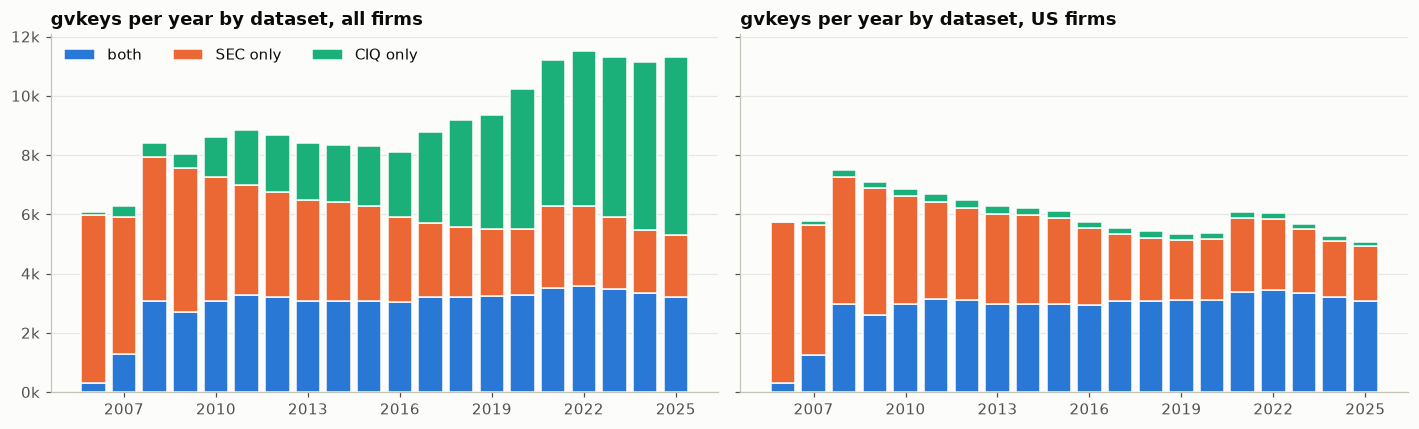

In [14]:
ciq_gy = calls.dropna(subset=['gvkey'])[['gvkey', 'year']].drop_duplicates().assign(ciq=1)
sec_gy = filings.dropna(subset=['gvkey'])[['gvkey', 'year']].drop_duplicates().assign(sec=1)
gy = ciq_gy.merge(sec_gy, on=['gvkey', 'year'], how='outer').merge(comp[['gvkey', 'region']], on='gvkey', how='left')
gy['status'] = np.select([gy.ciq.notna() & gy.sec.notna(), gy.sec.notna()], ['both', 'SEC only'], 'CIQ only')

joint = pd.concat({'all': gy.pivot_table(index='year', columns='status', values='gvkey', aggfunc='size'),
                   'US': gy[gy.region.eq('United States')].pivot_table(index='year', columns='status', values='gvkey', aggfunc='size')},
                  axis=1).fillna(0)
for k in ['all', 'US']:
    joint[(k, 'both / SEC')] = joint[(k, 'both')] / (joint[(k, 'both')] + joint[(k, 'SEC only')])

yr = joint.loc[2006:LAST_FULL]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, k in zip(axes, ['all', 'US']):
    bottom = np.zeros(len(yr))
    for status, c in zip(['both', 'SEC only', 'CIQ only'], [BLUE, ORANGE, AQUA]):
        ax.bar(yr.index, yr[(k, status)], bottom=bottom, color=c, width=0.8, label=status,
               edgecolor=SURFACE, linewidth=1)
        bottom += yr[(k, status)].values
    ax.set_title(f'gvkeys per year by dataset, {k} firms'); ax.yaxis.set_major_formatter(kfmt)
    ax.xaxis.set_major_locator(YEARS)
    ax.grid(axis='x', visible=False)
axes[0].legend(loc='upper left', ncol=3)
plt.tight_layout(); plt.show()

joint.loc[SEL_YEARS].style.format('{:,.0f}').format('{:.0%}', subset=[('all', 'both / SEC'), ('US', 'both / SEC')])

In [15]:
# Event level: does each earnings 8-K have a CIQ call for the same gvkey within 3 days?
e8 = ea8k.dropna(subset=['gvkey']).query('year >= 2008').sort_values('fdate')[['gvkey', 'fdate', 'year', 'us']]
cl = calls.dropna(subset=['gvkey']).sort_values('call_date')[['gvkey', 'call_date']]
mm = pd.merge_asof(e8, cl, left_on='fdate', right_on='call_date', by='gvkey',
                   tolerance=pd.Timedelta('3D'), direction='nearest')
mm['matched'] = mm.call_date.notna()
mm['days'] = (mm.call_date - mm.fdate).dt.days
ev = pd.DataFrame({'all 8-K 2.02': mm.groupby('year').matched.mean(),
                   'US 8-K 2.02': mm[mm.us].groupby('year').matched.mean()})
display(ev.loc[SEL_YEARS].T.style.format('{:.0%}').set_caption('Share of Item 2.02 8-Ks with a CIQ call within 3 days'))
print('Call date minus 8-K filing date, matched pairs:',
      mm.days.value_counts(normalize=True).sort_index().map('{:.1%}'.format).to_dict())

year,2008,2012,2016,2020,2024,2025
all 8-K 2.02,43%,65%,63%,70%,71%,71%
US 8-K 2.02,43%,65%,63%,69%,71%,71%


Call date minus 8-K filing date, matched pairs: {-3.0: '0.4%', -2.0: '0.6%', -1.0: '2.7%', 0.0: '78.7%', 1.0: '17.1%', 2.0: '0.2%', 3.0: '0.2%'}


Among US gvkeys that file with the SEC, the share that also has CIQ calls rose from 41% (2008) to about 62-63% (2024-2025): about **3.1-3.2k US firms a year are in both datasets**. Almost every US CIQ firm is also an SEC filer (only about 120 US "CIQ only" firms). The large "CIQ only" block overall is non-US firms.

At the event level, 71% of earnings 8-Ks (since 2020) have a matching CIQ call within 3 days. The call is on the 8-K date 79% of the time and the next day 17% of the time.

## 13. Summary

| | CIQ earnings calls | SEC 10-K / 10-Q | SEC 8-K Item 2.02 |
|---|---|---|---|
| Usable from | 2008 | 1996 (acceptance time from 2004) | 2004 |
| Latest date | 2026-10-09 | 2026-10-19 | 2026-10-19 |
| Per year (recent) | ~30k calls, 9.3k firms | ~6.5k 10-K, ~17k 10-Q | ~17k filings, 4.2k firms |
| US firms per year | ~3.3k | ~4.9k (10-Q) | ~4.0k |
| gvkey link | 99.7% | 81% (87% recently; gaps are trusts) | 95% (99% recently) |
| Main caveats | 37% of scheduled calls never get a transcript; analyst firm empty since 2012; use version creation time | gvkey missing for ~13% (trusts); use the main document, not the full submission | EX-99.1 label 95%, any EX-99 98% |

**Usable overlap:** about 3.1-3.2k US firms a year appear in both datasets, and 71% of earnings 8-Ks have a CIQ call within 3 days (79% on the same day). Coverage is thinnest in Health Care and Financials.

In [16]:
db.close()